# Public Demo: Synthetic Supplier Data

This notebook uses fictional supplier names, IDs, countries, statuses, and purchase amounts. No rows or saved outputs from the original workbook are included.

In [ ]:
import pandas as pd
from pathlib import Path

DATA_FILE = Path("sample_data/Public_Synthetic_Supplier_Data.xlsx")
if not DATA_FILE.exists():
    DATA_FILE = Path("sample_data/Public_Synthetic_Supplier_Data.xlsx")
import seaborn as sns
import matplotlib.pyplot as plt

df_suppliers = dataframe = pd.read_excel(DATA_FILE, sheet_name="Supplier Directory")
df_purchases = pd.read_excel(DATA_FILE, sheet_name="Purchase Data 2023")

In [2]:
df_suppliers = df_suppliers.loc[:, ~df_suppliers.columns.str.contains('^Unnamed')]
df_suppliers

,Vendor ID,Supplier Name,Supplier Type,Country,Integration Status
0,PUB-0001,Fictional Supplier 001,Direct,AU,Completed
1,PUB-0002,Fictional Supplier 002,Direct,BR,Completed
2,PUB-0003,Fictional Supplier 003,Indirect,DE,Completed
3,PUB-0004,Fictional Supplier 004,Direct,IN,Pending
4,PUB-0005,Fictional Supplier 005,Direct,CA,Completed
...,...,...,...,...,...
115,PUB-0116,Fictional Supplier 116,Direct,IN,Pending
116,PUB-0117,Fictional Supplier 117,Indirect,DE,Completed
117,PUB-0118,Fictional Supplier 118,Direct,BR,Completed
118,PUB-0119,Fictional Supplier 119,Direct,GB,Completed


In [3]:
df_purchases

,Vendor ID,Purchase Amount (EUR Millions)
0,PUB-0001,11.13
1,PUB-0002,11.56
2,PUB-0003,18.05
3,PUB-0004,24.51
4,PUB-0005,22.13
...,...,...
115,PUB-0116,6.50
116,PUB-0117,6.98
117,PUB-0118,14.88
118,PUB-0119,7.34


In [4]:
# Check the first rows of the DataFrame
print("----- Supplier Directory -----")
print(df_suppliers.head())

----- Supplier Directory -----
  Vendor ID           Supplier Name Supplier Type Country Integration Status
0  PUB-0001  Fictional Supplier 001        Direct      AU          Completed
1  PUB-0002  Fictional Supplier 002        Direct      BR          Completed
2  PUB-0003  Fictional Supplier 003      Indirect      DE          Completed
3  PUB-0004  Fictional Supplier 004        Direct      IN            Pending
4  PUB-0005  Fictional Supplier 005        Direct      CA          Completed


In [5]:
# Check the first rows of the DataFrame
print("\n----- Purchase Data 2023 -----")
print(df_purchases.head())


----- Purchase Data 2023 -----
  Vendor ID  Purchase Amount (EUR Millions)
0  PUB-0001                           11.13
1  PUB-0002                           11.56
2  PUB-0003                           18.05
3  PUB-0004                           24.51
4  PUB-0005                           22.13


In [6]:
# 1. 2023 suppliers' total purchases in EUR (millions)

total_purchase_2023 = df_purchases["Purchase Amount (EUR Millions)"].sum()
print("2023 suppliers' total purchases in EUR (millions):", total_purchase_2023)

2023 suppliers' total purchases in EUR (millions): 1550.06


In [7]:
# 2. 2023 breakdown of suppliers' total purchases in EUR by direct and indirect suppliers

purchase_by_supplier_type = df_suppliers.merge(df_purchases, on="Vendor ID", how="left").groupby("Supplier Type")["Purchase Amount (EUR Millions)"].sum()
print("\n----- Breakdown of suppliers' total purchases in EUR by direct and indirect suppliers -----")
print(purchase_by_supplier_type)


----- Breakdown of suppliers' total purchases in EUR by direct and indirect suppliers -----
Supplier Type
Direct      1113.69
Indirect     436.37
Name: Purchase Amount (EUR Millions), dtype: float64


In [8]:
# 3. 2023 breakdown of suppliers' total purchases in EUR by country

purchase_by_country = df_suppliers.merge(df_purchases, on="Vendor ID", how="left").groupby("Country")["Purchase Amount (EUR Millions)"].sum()
print("\n----- Breakdown of suppliers' total purchases in EUR by country -----")
print(purchase_by_country)


----- Breakdown of suppliers' total purchases in EUR by country -----
Country
AU    171.31
BR    118.86
CA    131.99
DE    150.17
FR     43.67
GB    223.86
IN    128.68
JP    162.83
MX    257.28
US    161.41
Name: Purchase Amount (EUR Millions), dtype: float64


In [9]:
# 4.1. 2023 breakdown of suppliers' total purchases in EUR by Integration status

purchase_by_integration_status = df_suppliers.merge(df_purchases, on="Vendor ID", how="left").groupby("Integration Status")["Purchase Amount (EUR Millions)"].sum()
print("\n----- Breakdown of suppliers' total purchases in EUR by Integration status -----")
print(purchase_by_integration_status)


----- Breakdown of suppliers' total purchases in EUR by Integration status -----
Integration Status
Completed    1199.03
Pending       351.03
Name: Purchase Amount (EUR Millions), dtype: float64


In [10]:
# 4.2. Count suppliers that have not yet implemented Integration

suppliers_pending_integration = df_suppliers[df_suppliers["Integration Status"] == "Pending"]["Vendor ID"].nunique()
print("\n----- Number of suppliers that have not yet implemented Integration -----")
print("Number of suppliers:", suppliers_pending_integration)


----- Number of suppliers that have not yet implemented Integration -----
Number of suppliers: 30


In [11]:
# Check the unique values in the "Integration Status" column
print("Unique values in the 'Integration Status' column:")
print(df_suppliers["Integration Status"].unique())

Unique values in the 'Integration Status' column:
['Completed' 'Pending']


In [12]:
# 4.3) Indicate how many suppliers have Integration Implemented

suppliers_pending_integration = df_suppliers[df_suppliers["Integration Status"] == "Completed"]["Vendor ID"].nunique()
print("\n----- Number of Suppliers that have Integration Implemented -----")
print("Number of Suppliers:", suppliers_pending_integration)


----- Number of Suppliers that have Integration Implemented -----
Number of Suppliers: 90


In [13]:
# Configure the chart style
plt.style.use('ggplot')

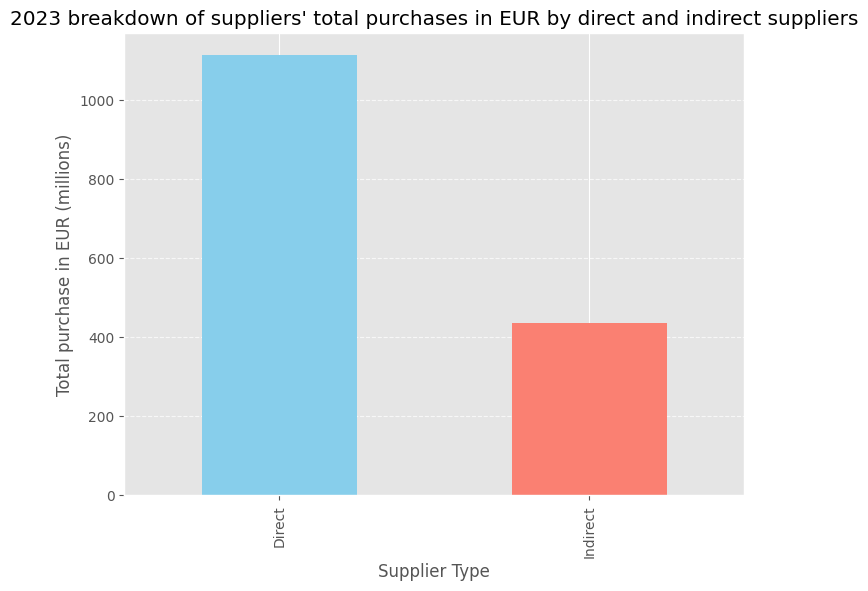

In [14]:
# Chart 2: 2023 breakdown of suppliers' total purchases in EUR by direct and indirect suppliers
purchase_by_supplier_type.plot(kind='bar', figsize=(8, 6), color=['skyblue', 'salmon'])
plt.ylabel("Total purchase in EUR (millions)")
plt.title("2023 breakdown of suppliers' total purchases in EUR by direct and indirect suppliers")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

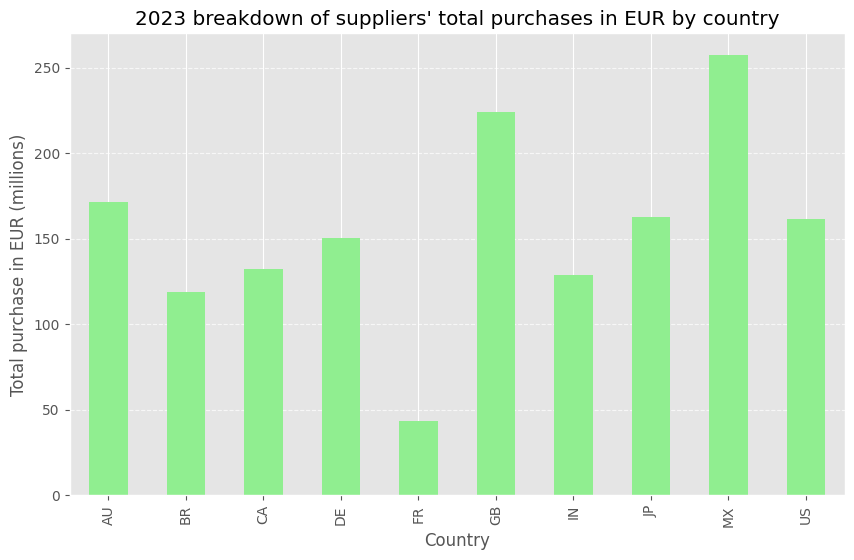

In [15]:
# Chart 3: 2023 breakdown of suppliers' total purchases in EUR by country

purchase_by_country.plot(kind='bar', figsize=(10, 6), color='lightgreen')
plt.ylabel("Total purchase in EUR (millions)")
plt.xlabel("Country")
plt.title("2023 breakdown of suppliers' total purchases in EUR by country")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# purchase_by_country.plot(kind='bar', figsize=(10, 6), color='lightgreen')
# plt.ylabel("Total purchase in EUR (millions)")
# plt.xlabel("Country")
# plt.title("2023 breakdown of suppliers' total purchases in EUR by country")
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.xticks(range(len(purchase_by_country.index)), purchase_by_country["Country"])
# plt.show()

  Country  TOTAL Purchase in EUR (Millions)
0      MX                            257.28
1      GB                            223.86
2      AU                            171.31
3      JP                            162.83
4      US                            161.41


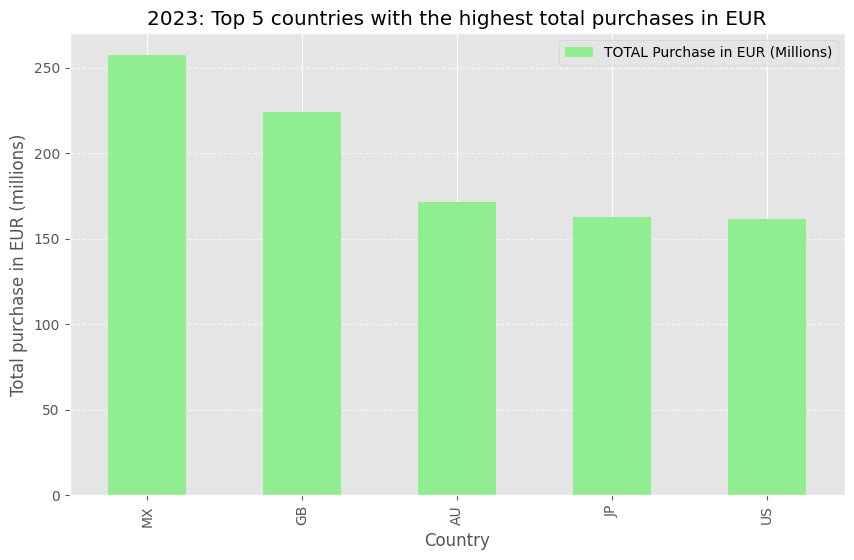

In [16]:
# print("\n----- Breakdown of suppliers' total purchases in EUR by country -----")
# print("\n----- Top 5 countries with the highest total purchases in EUR -----")

# top_5_countries = purchase_by_country.nlargest(5, "Purchase Amount (EUR Millions)")
top_5_countries = purchase_by_country.nlargest(5).reset_index(name="TOTAL Purchase in EUR (Millions)")
print(top_5_countries)

# print(top_5_countries)


# Plot the top 5 countries
top_5_countries.plot(kind='bar', figsize=(10, 6), color='lightgreen')
plt.ylabel("Total purchase in EUR (millions)")
plt.title("2023: Top 5 countries with the highest total purchases in EUR")
plt.xlabel("Country")
plt.xticks(range(5), top_5_countries["Country"])
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("top5countries.png")
plt.show()

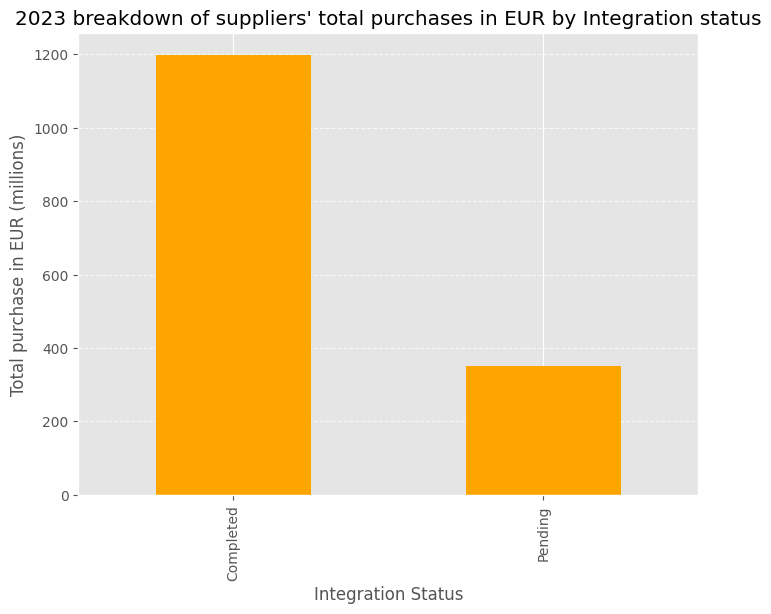

In [17]:
# Chart 4.1: 2023 breakdown of suppliers' total purchases in EUR by Integration status
# CHECK WHETHER THIS NEEDS TO BE FIXED

purchase_by_integration_status.plot(kind='bar', figsize=(8, 6), color='orange')
plt.ylabel("Total purchase in EUR (millions)")
plt.title("2023 breakdown of suppliers' total purchases in EUR by Integration status")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [18]:
# 5.1. Propose a project timeline for suppliers that have not yet implemented Integration

# Rank suppliers by total purchase volume
df_suppliers = df_suppliers.merge(df_purchases, on="Vendor ID", how="left")
df_suppliers["Supplier Relevance"] = df_suppliers["Purchase Amount (EUR Millions)"].rank(pct=True)


# Divide suppliers into waves
wave1 = df_suppliers[(df_suppliers["Integration Status"] == "Pending") & (df_suppliers["Supplier Relevance"] <= 0.5)]
wave2 = df_suppliers[(df_suppliers["Integration Status"] == "Pending") & (df_suppliers["Supplier Relevance"] > 0.5) & (df_suppliers["Supplier Relevance"] <= 0.85)]
wave3 = df_suppliers[(df_suppliers["Integration Status"] == "Pending") & (df_suppliers["Supplier Relevance"] > 0.85)]

print("\n----- Proposed timeline for Integration implementation -----")
print("Wave 1 - 0-50% relevance:")
print(wave1[["Vendor ID", "Supplier Name", "Purchase Amount (EUR Millions)"]])

print("\nWave 2 - 51-85% relevance:")
print(wave2[["Vendor ID", "Supplier Name", "Purchase Amount (EUR Millions)"]])

print("\nWave 3 - 86-100% relevance:")
print(wave3[["Vendor ID", "Supplier Name", "Purchase Amount (EUR Millions)"]])


----- Proposed timeline for Integration implementation -----
Wave 1 - 0-50% relevance:
    Vendor ID           Supplier Name  Purchase Amount (EUR Millions)
11   PUB-0012  Fictional Supplier 012                            7.88
15   PUB-0016  Fictional Supplier 016                            4.74
23   PUB-0024  Fictional Supplier 024                           12.26
35   PUB-0036  Fictional Supplier 036                           10.93
39   PUB-0040  Fictional Supplier 040                            5.64
43   PUB-0044  Fictional Supplier 044                            5.95
51   PUB-0052  Fictional Supplier 052                            4.98
59   PUB-0060  Fictional Supplier 060                            0.16
67   PUB-0068  Fictional Supplier 068                            6.82
71   PUB-0072  Fictional Supplier 072                           11.36
79   PUB-0080  Fictional Supplier 080                            3.49
83   PUB-0084  Fictional Supplier 084                            4.37
87